# ECG Classification — Top 5 Labels

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image

In [2]:
DATA_DIR = Path("data/processed/12sl_median_images_final")

NUM_LABELS = 5

MODEL_DIR = DATA_DIR / f"top_{NUM_LABELS}"

MODEL_DIR.mkdir(exist_ok=True)


In [3]:
df = pd.read_csv(DATA_DIR / "training_index.csv")
metadata = pd.read_csv("ptbxl_database.csv")

In [4]:
print("Dataset shape:", df.shape)
print("Metadata shape:", metadata.shape)

Dataset shape: (20914, 158)
Metadata shape: (21799, 28)


In [5]:
df.head()

,ecg_id,image_path,label_$SABCOND,label_$SCAPTUR,label_$SFUS,label_$SIVR,label_$SRETC,label_$SWQR,label_2ST,label_AB,...,label_VESC,label_VPCX,label_VPR,label_W2T1,label_W3T1,label_W4T1,label_WPW,label_WPWA,label_WPWB,label_WQTACH
0,1,images/00001.png,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2,images/00002.png,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,3,images/00003.png,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,images/00004.png,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,5,images/00005.png,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [6]:
df = df.merge(
    metadata[["ecg_id", "patient_id", "strat_fold"]],
    on="ecg_id",
    how="left",
    validate="one_to_one"
)

In [7]:
assert df["patient_id"].notna().all()
assert df["strat_fold"].notna().all()

In [8]:
print("Total ECGs:", len(df))
print("Unique patients:", df["patient_id"].nunique())
print("\nFold distribution:")
print(df["strat_fold"].value_counts().sort_index())

Total ECGs: 20914
Unique patients: 18202

Fold distribution:
strat_fold
1     2065
2     2088
3     2090
4     2100
5     2066
6     2062
7     2067
8     2070
9     2148
10    2158
Name: count, dtype: int64


In [9]:
train_df = df[df["strat_fold"].between(1, 8)].copy()
val_df = df[df["strat_fold"] == 9].copy()
test_df = df[df["strat_fold"] == 10].copy()

In [10]:
assert set(train_df.patient_id).isdisjoint(val_df.patient_id)
assert set(train_df.patient_id).isdisjoint(test_df.patient_id)
assert set(val_df.patient_id).isdisjoint(test_df.patient_id)

print("Training records:", len(train_df))
print("Validation records:", len(val_df))
print("Testing records:", len(test_df))

print("\nNo patient leakage detected.")

Training records: 16608
Validation records: 2148
Testing records: 2158

No patient leakage detected.


Original labels: 156
Selected labels: 5
['label_NSR', 'label_AB', 'label_NML', 'label_SBRAD', 'label_SRTH']


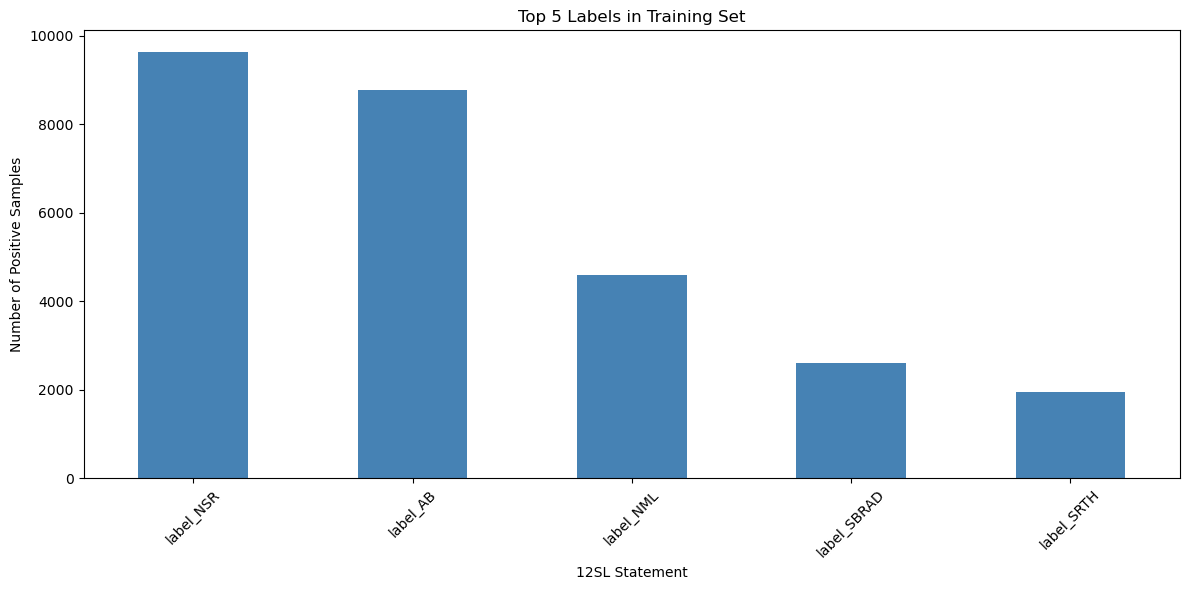

In [11]:
label_cols = [
    col for col in df.columns
    if col.startswith("label_")
]

label_counts = train_df[label_cols].sum().sort_values(
    ascending=False,
    kind="stable"
)

selected_labels = label_counts.head(NUM_LABELS).index.tolist()

print("Original labels:", len(label_cols))
print("Selected labels:", len(selected_labels))

print(selected_labels)

plt.figure(figsize=(12, 6))

label_counts.head(NUM_LABELS).plot(
    kind="bar", color="steelblue"
)

plt.title(f"Top {NUM_LABELS} Labels in Training Set")
plt.ylabel("Number of Positive Samples")
plt.xlabel("12SL Statement")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [12]:
def preprocess_ecg(image_path):

    image = Image.open(image_path).convert("RGB")
    image = np.array(image)

    panels = []

    for row in range(4):
        row_panels = []

        for col in range(3):

            x0 = 28 + 390 * col
            x1 = 391 + 390 * col

            y0 = 102 + 280 * row
            y1 = 335 + 280 * row

            panel = image[y0:y1, x0:x1]

            # Extract dark ECG trace and remove red grid
            waveform = (panel[:, :, 0] < 100).astype(
                np.uint8
            ) * 255

            row_panels.append(waveform)

        panels.append(np.concatenate(row_panels, axis=1))

    processed = np.concatenate(panels, axis=0)

    return processed

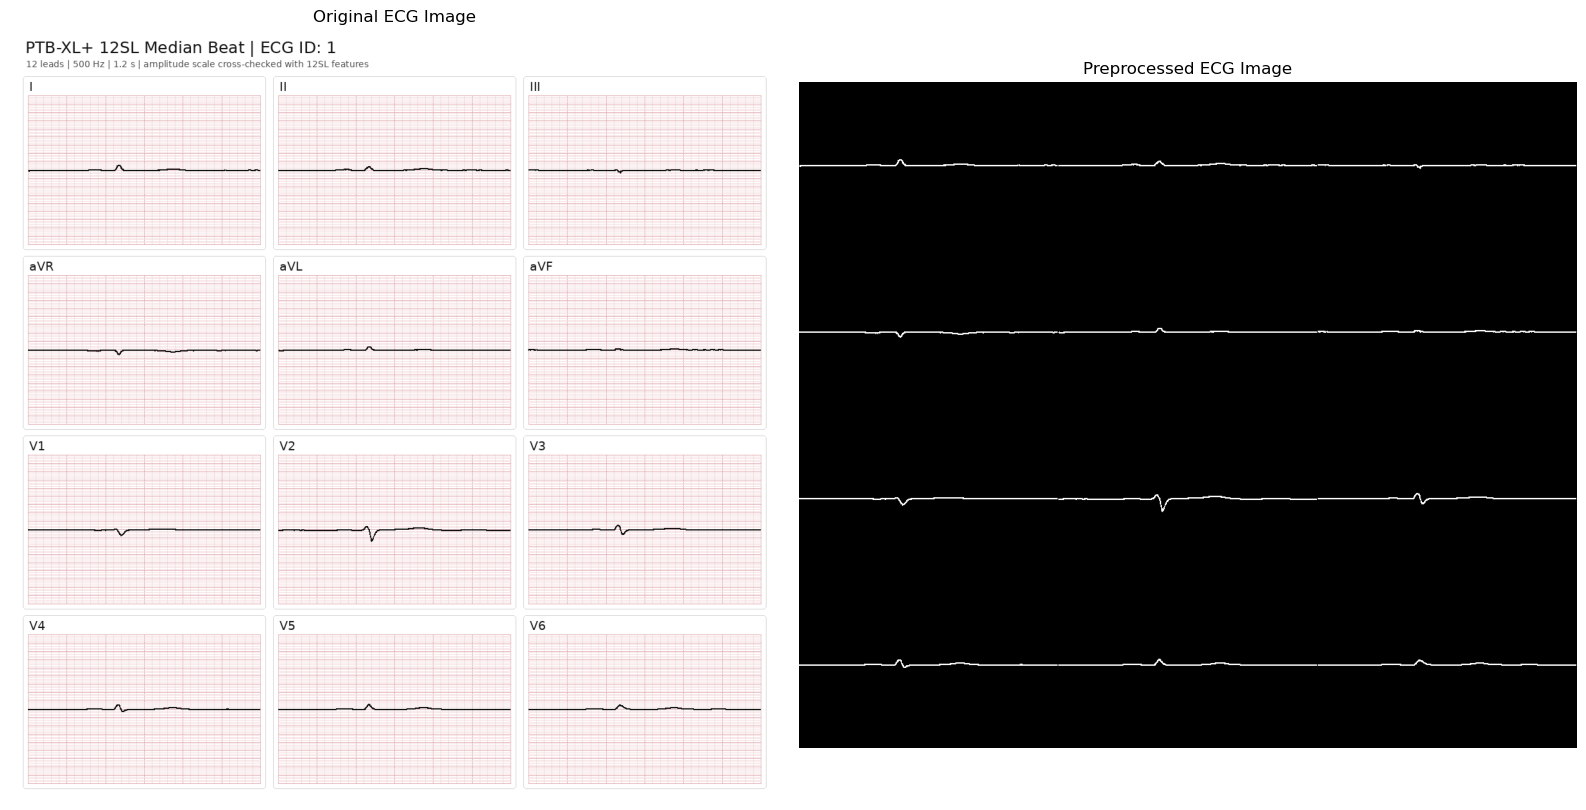

Processed image shape: (932, 1089)


In [13]:
sample = train_df.iloc[0]

image_path = DATA_DIR / sample["image_path"]

original = Image.open(image_path)
processed = preprocess_ecg(image_path)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

axes[0].imshow(original)
axes[0].set_title("Original ECG Image")
axes[0].axis("off")

axes[1].imshow(processed, cmap="gray")
axes[1].set_title("Preprocessed ECG Image")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print("Processed image shape:", processed.shape)

In [14]:
distribution = pd.DataFrame({
    "Train": train_df[selected_labels].sum(),
    "Validation": val_df[selected_labels].sum(),
    "Test": test_df[selected_labels].sum()
})

print(distribution)

print("\nLabels without positive validation examples:")
print(distribution[distribution["Validation"] == 0])

print("\nLabels without positive test examples:")
print(distribution[distribution["Test"] == 0])

             Train  Validation  Test
label_NSR     9641        1253  1255
label_AB      8770        1069  1074
label_NML     4590         635   627
label_SBRAD   2594         317   342
label_SRTH    1939         255   265

Labels without positive validation examples:
Empty DataFrame
Columns: [Train, Validation, Test]
Index: []

Labels without positive test examples:
Empty DataFrame
Columns: [Train, Validation, Test]
Index: []


In [15]:
import json

with open(MODEL_DIR / "selected_labels.json", "w") as f:

    json.dump(selected_labels, f, indent=4)

distribution.to_csv(
    MODEL_DIR / "label_distribution.csv"
)


## Model Training

In [16]:
from skimage.feature import hog
from tqdm.auto import tqdm

from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    f1_score,
    precision_score,
    recall_score
)

import joblib

/usr/lib/python3/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [17]:
def extract_hog_features(image_path):

    image = preprocess_ecg(image_path)

    features = []

    for row in range(4):
        for col in range(3):

            lead = image[
                row * 233 : (row + 1) * 233,
                col * 363 : (col + 1) * 363
            ]

            lead_features = hog(
                lead,
                orientations=9,
                pixels_per_cell=(48, 60),
                cells_per_block=(2, 2),
                block_norm="L2-Hys",
                feature_vector=True
            )

            features.append(lead_features)

    return np.concatenate(features).astype(np.float32)

In [18]:
sample_path = DATA_DIR / train_df.iloc[0]["image_path"]

sample_features = extract_hog_features(sample_path)

print("Original preprocessed shape:",
      preprocess_ecg(sample_path).shape)

print("HOG feature shape:", sample_features.shape)
print("First 20 features:", sample_features[:20])

Original preprocessed shape: (932, 1089)
HOG feature shape: (6480,)
First 20 features: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [19]:
def prepare_features(dataframe, split_name):

    first_image = DATA_DIR / dataframe.iloc[0]["image_path"]
    n_features = len(extract_hog_features(first_image))

    X = np.empty(
        (len(dataframe), n_features),
        dtype=np.float32
    )

    for i, path in enumerate(
        tqdm(dataframe["image_path"],
             desc=f"Extracting {split_name} features")
    ):
        X[i] = extract_hog_features(DATA_DIR / path)

    y = dataframe[selected_labels].to_numpy(
        dtype=np.uint8
    )

    return X, y

In [20]:
FEATURE_DIR = DATA_DIR / "hog_features"

X_train = np.load(FEATURE_DIR / "X_train.npy", mmap_mode="r")
X_val = np.load(FEATURE_DIR / "X_val.npy", mmap_mode="r")
X_test = np.load(FEATURE_DIR / "X_test.npy", mmap_mode="r")

with open(DATA_DIR / "selected_labels.json") as f:

    original_labels = json.load(f)

assert np.array_equal(
    np.load(FEATURE_DIR / "y_train.npy"),
    train_df[original_labels].to_numpy(dtype=np.uint8)
)

assert np.array_equal(
    np.load(FEATURE_DIR / "y_val.npy"),
    val_df[original_labels].to_numpy(dtype=np.uint8)
)

assert np.array_equal(
    np.load(FEATURE_DIR / "y_test.npy"),
    test_df[original_labels].to_numpy(dtype=np.uint8)
)


In [21]:
y_train = train_df[selected_labels].to_numpy(dtype=np.uint8)
y_val = val_df[selected_labels].to_numpy(dtype=np.uint8)
y_test = test_df[selected_labels].to_numpy(dtype=np.uint8)

assert X_train.shape == (len(train_df), 6480)
assert X_val.shape == (len(val_df), 6480)
assert X_test.shape == (len(test_df), 6480)

assert (y_train.sum(axis=0) > 0).all()
assert (y_train.sum(axis=0) < len(y_train)).all()
assert (y_val.sum(axis=0) > 0).all()
assert (y_val.sum(axis=0) < len(y_val)).all()

np.save(MODEL_DIR / "y_train.npy", y_train)
np.save(MODEL_DIR / "y_val.npy", y_val)
np.save(MODEL_DIR / "y_test.npy", y_test)

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)


Training: (16608, 6480) (16608, 5)
Validation: (2148, 6480) (2148, 5)
Testing: (2158, 6480) (2158, 5)


## Logistic Regression 

In [22]:
lr_model = OneVsRestClassifier(
    LogisticRegression(
        C=1.0,
        max_iter=1000,
        solver="liblinear",
        random_state=42
    ),
    n_jobs=1
)

lr_model.fit(X_train, y_train)

print("Logistic Regression training completed.")

joblib.dump(lr_model, MODEL_DIR / "logistic_regression.pkl")


Logistic Regression training completed.


['data/processed/12sl_median_images_final/top_5/logistic_regression.pkl']

In [23]:
lr_val_probs = lr_model.predict_proba(X_val)

lr_val_preds = (lr_val_probs >= 0.5).astype(int)

print("Macro AUROC:",
      roc_auc_score(y_val, lr_val_probs, average="macro"))

print("Macro AUPRC:",
      average_precision_score(y_val, lr_val_probs,
                              average="macro"))

print("Macro F1:",
      f1_score(y_val, lr_val_preds,
               average="macro", zero_division=0))

print("Micro F1:",
      f1_score(y_val, lr_val_preds,
               average="micro", zero_division=0))

Macro AUROC: 0.8496348478158934
Macro AUPRC: 0.6878850108840026
Macro F1: 0.592453565932032
Micro F1: 0.7470990776554597


# SVM

In [24]:
from sklearn.svm import LinearSVC

In [25]:
svm_model = OneVsRestClassifier(
    LinearSVC(
        C=1.0,
        dual=False,
        max_iter=5000,
        random_state=42
    ),
    n_jobs=1,
    verbose=10
)

In [26]:
svm_model.fit(X_train, y_train)

[Parallel(n_jobs=1)]: Done   1 tasks      | elapsed:    8.3s
[Parallel(n_jobs=1)]: Done   4 tasks      | elapsed:   23.8s
[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:   33.8s finished


,"estimator estimator: estimator objectA regressor or a classifier that implements :term:`fit`.When a classifier is passed, :term:`decision_function` will be usedin priority and it will fallback to :term:`predict_proba` if it is notavailable.When a regressor is passed, :term:`predict` is used.",LinearSVC(dua...ndom_state=42)
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation: the `n_classes`one-vs-rest problems are computed in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: 0.20 `n_jobs` default changed from 1 to None",1
,"verbose verbose: int, default=0The verbosity level, if non zero, progress messages are printed.Below 50, the output is sent to stderr. Otherwise, the output is sentto stdout. The frequency of the messages increases with the verbositylevel, reporting all iterations at 10. See :class:`joblib.Parallel` formore details... versionadded:: 1.1",10
Name,Type,Value
"classes_ classes_: array, shape = [`n_classes`]Class labels.","ndarray[int64](5,)","[0,1,2,3,4]"
estimators_ estimators_: list of `n_classes` estimatorsEstimators used for predictions.,list,"[LinearSVC(dua...ndom_state=42), LinearSVC(dua...ndom_state=42), LinearSVC(dua...ndom_state=42), LinearSVC(dua...ndom_state=42), ...]"
label_binarizer_ label_binarizer_: LabelBinarizer objectObject used to transform multiclass labels to binary labels andvice-versa.,LabelBinarizer,LabelBinarize...e_output=True)
multilabel_ multilabel_: booleanWhether a OneVsRestClassifier is a multilabel classifier.,bool,True
n_classes_ n_classes_: intNumber of classes.,int,5
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 0.24,int,6480
,"dual dual: ""auto"" or bool, default=""auto""Select the algorithm to either solve the dual or primaloptimization problem. Prefer dual=False when n_samples > n_features.`dual=""auto""` will choose the value of the parameter automatically,based on the values of `n_samples`, `n_features`, `loss`, `multi_class`and `penalty`. If `n_samples` < `n_features` and optimizer supportschosen `loss`, `multi_class` and `penalty`, then dual will be set to True,otherwise it will be set to False... versionchanged:: 1.3 The `""auto""` option is added in version 1.3 and will be the default in version 1.5.",False


In [27]:
print("SVM training completed.")

joblib.dump(
    svm_model,
    MODEL_DIR / "linear_svm.pkl"
)


SVM training completed.


['data/processed/12sl_median_images_final/top_5/linear_svm.pkl']

In [28]:
svm_val_scores = svm_model.decision_function(X_val)

svm_val_preds = (svm_val_scores >= 0).astype(int)

print("Macro AUROC:",
      roc_auc_score(y_val, svm_val_scores, average="macro"))

print("Macro AUPRC:",
      average_precision_score(y_val, svm_val_scores,
                              average="macro"))

print("Macro F1:",
      f1_score(y_val, svm_val_preds,
               average="macro", zero_division=0))

print("Micro F1:",
      f1_score(y_val, svm_val_preds,
               average="micro", zero_division=0))

Macro AUROC: 0.8530843725184678
Macro AUPRC: 0.6933456114403195
Macro F1: 0.6036011290974832
Micro F1: 0.7575174048289143


## Random Forest

In [29]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.multiclass import OneVsRestClassifier

In [30]:
rf_model = OneVsRestClassifier(
    RandomForestClassifier(
        n_estimators=100,
        max_depth=18,
        min_samples_leaf=3,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    ),
    n_jobs=1
)

rf_model.fit(X_train, y_train)

print("Random Forest training completed.")

joblib.dump(
    rf_model,
    MODEL_DIR / "random_forest.pkl"
)


Random Forest training completed.


['data/processed/12sl_median_images_final/top_5/random_forest.pkl']

In [31]:
rf_val_probs = rf_model.predict_proba(X_val)

rf_val_preds = (rf_val_probs >= 0.5).astype(int)

print("Macro AUROC:",
      roc_auc_score(y_val, rf_val_probs, average="macro"))

print("Macro AUPRC:",
      average_precision_score(y_val, rf_val_probs,
                              average="macro"))

print("Macro F1:",
      f1_score(y_val, rf_val_preds,
               average="macro", zero_division=0))

print("Micro F1:",
      f1_score(y_val, rf_val_preds,
               average="micro", zero_division=0))

Macro AUROC: 0.8562576061805199
Macro AUPRC: 0.6938120923272122
Macro F1: 0.5690230899774533
Micro F1: 0.752


In [32]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "SVM", "Random Forest"],

    "Macro AUROC": [
        roc_auc_score(y_val, lr_val_probs, average="macro"),
        roc_auc_score(y_val, svm_val_scores, average="macro"),
        roc_auc_score(y_val, rf_val_probs, average="macro")
    ],

    "Macro AUPRC": [
        average_precision_score(y_val, lr_val_probs,
                                average="macro"),
        average_precision_score(y_val, svm_val_scores,
                                average="macro"),
        average_precision_score(y_val, rf_val_probs,
                                average="macro")
    ],

    "Macro F1": [
        f1_score(y_val, lr_val_preds,
                 average="macro", zero_division=0),
        f1_score(y_val, svm_val_preds,
                 average="macro", zero_division=0),
        f1_score(y_val, rf_val_preds,
                 average="macro", zero_division=0)
    ],

    "Micro F1": [
        f1_score(y_val, lr_val_preds, average="micro"),
        f1_score(y_val, svm_val_preds, average="micro"),
        f1_score(y_val, rf_val_preds, average="micro")
    ]
})

display(results.round(4))

,Model,Macro AUROC,Macro AUPRC,Macro F1,Micro F1
0,Logistic Regression,0.8496,0.6879,0.5925,0.7471
1,SVM,0.8531,0.6933,0.6036,0.7575
2,Random Forest,0.8563,0.6938,0.5690,0.7520


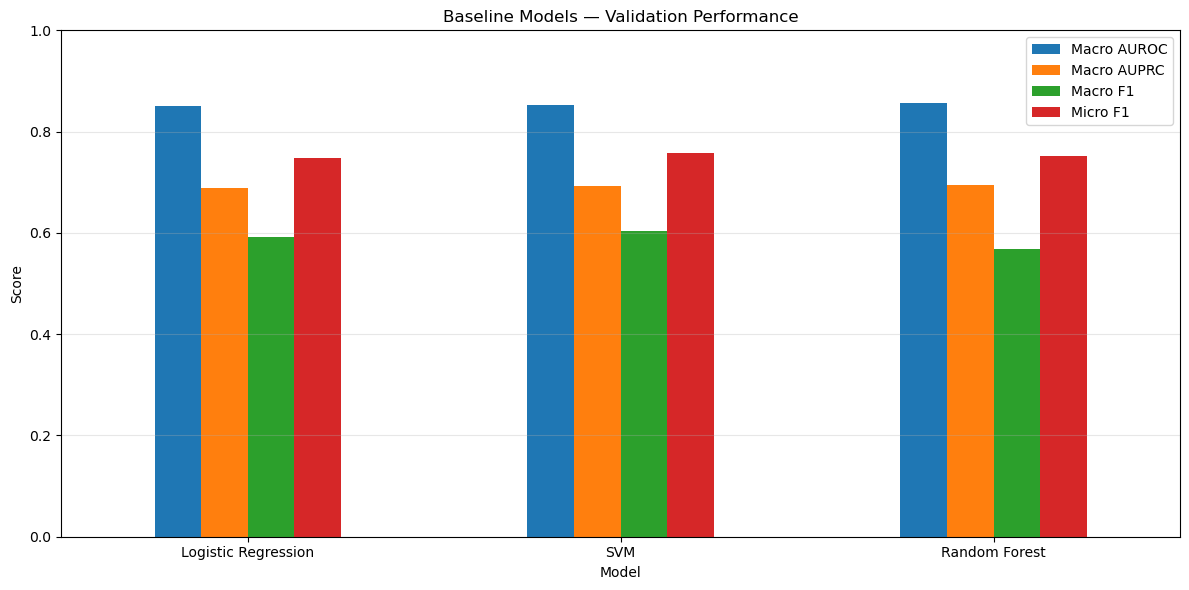

In [33]:
results.set_index("Model").plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1),
    rot=0
)

plt.title("Baseline Models — Validation Performance")
plt.ylabel("Score")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 2D CNN

In [34]:
import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader

In [35]:
torch.manual_seed(42)
np.random.seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: NVIDIA GeForce RTX 3050 Laptop GPU


In [36]:
class ECGDataset(Dataset):

    def __init__(self, dataframe, data_dir, labels):

        self.paths = dataframe["image_path"].tolist()
        self.targets = dataframe[labels].to_numpy(
            dtype=np.float32, copy=True
        )
        self.data_dir = data_dir

    def __len__(self):

        return len(self.paths)

    def __getitem__(self, idx):

        image_path = self.data_dir / self.paths[idx]

        image = preprocess_ecg(image_path)

        leads = []

        for row in range(4):
            for col in range(3):

                panel = image[
                    row * 233 : (row + 1) * 233,
                    col * 363 : (col + 1) * 363
                ]

                leads.append(panel)

        image = np.stack(leads, axis=0)

        image = torch.from_numpy(image).float() / 255.0

        target = torch.from_numpy(self.targets[idx])

        return image, target


In [37]:
train_dataset = ECGDataset(
    train_df, DATA_DIR, selected_labels
)

val_dataset = ECGDataset(
    val_df, DATA_DIR, selected_labels
)

test_dataset = ECGDataset(
    test_df, DATA_DIR, selected_labels
)

In [38]:
BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

In [39]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

Image batch shape: torch.Size([16, 12, 233, 363])
Label batch shape: torch.Size([16, 5])


In [40]:
class ECGCNN(nn.Module):

    def __init__(self, num_classes):

        super().__init__()

        def conv_block(in_channels, out_channels):

            return nn.Sequential(
                nn.Conv2d(
                    in_channels,
                    out_channels,
                    kernel_size=3,
                    padding=1,
                    bias=False
                ),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(inplace=True),
                nn.MaxPool2d(2)
            )

        self.features = nn.Sequential(
            conv_block(12, 32),
            conv_block(32, 64),
            conv_block(64, 128),
            conv_block(128, 256)
        )

        self.pool = nn.AdaptiveAvgPool2d((4, 8))

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 4 * 8, 256),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):

        x = self.features(x)
        x = self.pool(x)
        x = self.classifier(x)

        return x

In [41]:
model = ECGCNN(
    num_classes=len(selected_labels)
).to(device)

print(model)

print("Trainable parameters:",
      sum(p.numel() for p in model.parameters()
          if p.requires_grad))

ECGCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(12, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=

In [42]:
EPOCHS = 30
LEARNING_RATE = 0.0003
PATIENCE = 5

In [43]:
criterion = nn.BCEWithLogitsLoss()

In [44]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-4
)

In [45]:
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

In [46]:
BEST_MODEL_PATH = MODEL_DIR / "cnn_best.pt"


In [47]:
print("Training device:", device)
print("Number of classes:", len(selected_labels))

Training device: cuda
Number of classes: 5


In [48]:
def train_one_epoch(model, loader, optimizer, criterion):

    model.train()

    running_loss = 0.0

    for images, targets in tqdm(loader, desc="Training", leave=False):

        images = images.to(device)
        targets = targets.to(device)

        optimizer.zero_grad(set_to_none=True)

        # Forward propagation
        logits = model(images)

        # Calculate loss
        loss = criterion(logits, targets)

        # Backpropagation
        loss.backward()

        # Update parameters
        optimizer.step()

        running_loss += loss.item() * images.size(0)

    return running_loss / len(loader.dataset)

In [49]:
def evaluate_model(model, loader, criterion):

    model.eval()

    running_loss = 0.0

    all_targets = []
    all_probs = []

    with torch.no_grad():

        for images, targets in tqdm(
            loader, desc="Evaluating", leave=False
        ):

            images = images.to(device)
            targets = targets.to(device)

            logits = model(images)

            loss = criterion(logits, targets)

            probs = torch.sigmoid(logits)

            running_loss += loss.item() * images.size(0)

            all_targets.append(targets.cpu().numpy())
            all_probs.append(probs.cpu().numpy())

    y_true = np.concatenate(all_targets, axis=0)
    y_probs = np.concatenate(all_probs, axis=0)

    y_preds = (y_probs >= 0.5).astype(int)

    metrics = {
        "loss": running_loss / len(loader.dataset),

        "macro_auroc": roc_auc_score(
            y_true, y_probs, average="macro"
        ),

        "macro_auprc": average_precision_score(
            y_true, y_probs, average="macro"
        ),

        "macro_f1": f1_score(
            y_true, y_preds,
            average="macro", zero_division=0
        ),

        "micro_f1": f1_score(
            y_true, y_preds,
            average="micro", zero_division=0
        )
    }

    return metrics, y_true, y_probs

In [50]:
history = {
    "train_loss": [],
    "val_loss": [],
    "macro_auroc": [],
    "macro_auprc": [],
    "macro_f1": [],
    "micro_f1": []
}

best_auprc = -np.inf
best_epoch = 0
epochs_without_improvement = 0

In [51]:
for epoch in range(EPOCHS):

    train_loss = train_one_epoch(
        model,
        train_loader,
        optimizer,
        criterion
    )

    val_metrics, _, _ = evaluate_model(
        model,
        val_loader,
        criterion
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_metrics["loss"])
    history["macro_auroc"].append(val_metrics["macro_auroc"])
    history["macro_auprc"].append(val_metrics["macro_auprc"])
    history["macro_f1"].append(val_metrics["macro_f1"])
    history["micro_f1"].append(val_metrics["micro_f1"])

    scheduler.step(val_metrics["macro_auprc"])

    print(
        f"Epoch [{epoch+1:02d}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_metrics['loss']:.4f} | "
        f"AUROC: {val_metrics['macro_auroc']:.4f} | "
        f"AUPRC: {val_metrics['macro_auprc']:.4f} | "
        f"Macro F1: {val_metrics['macro_f1']:.4f}"
    )

    if val_metrics["macro_auprc"] > best_auprc:

        best_auprc = val_metrics["macro_auprc"]
        best_epoch = epoch + 1

        torch.save(
            model.state_dict(),
            BEST_MODEL_PATH
        )

        epochs_without_improvement = 0

        print("Best model saved.")

    else:

        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:

        print("Early stopping triggered.")
        break

Epoch [01/30] | Train Loss: 0.3986 | Val Loss: 0.3242 | AUROC: 0.8782 | AUPRC: 0.7188 | Macro F1: 0.6101
Best model saved.


Epoch [02/30] | Train Loss: 0.3258 | Val Loss: 0.3158 | AUROC: 0.8887 | AUPRC: 0.7407 | Macro F1: 0.6200
Best model saved.


Epoch [03/30] | Train Loss: 0.3106 | Val Loss: 0.2954 | AUROC: 0.8933 | AUPRC: 0.7481 | Macro F1: 0.6283
Best model saved.


Epoch [04/30] | Train Loss: 0.2958 | Val Loss: 0.2785 | AUROC: 0.9051 | AUPRC: 0.7714 | Macro F1: 0.6605
Best model saved.


Epoch [05/30] | Train Loss: 0.2877 | Val Loss: 0.2762 | AUROC: 0.9061 | AUPRC: 0.7742 | Macro F1: 0.6528
Best model saved.


Epoch [06/30] | Train Loss: 0.2824 | Val Loss: 0.2716 | AUROC: 0.9091 | AUPRC: 0.7853 | Macro F1: 0.6825
Best model saved.


... (6 outputs left out)

Epoch [13/30] | Train Loss: 0.2341 | Val Loss: 0.2904 | AUROC: 0.9068 | AUPRC: 0.7857 | Macro F1: 0.6861


Epoch [14/30] | Train Loss: 0.2279 | Val Loss: 0.2785 | AUROC: 0.9116 | AUPRC: 0.7939 | Macro F1: 0.7133


Epoch [15/30] | Train Loss: 0.1982 | Val Loss: 0.2985 | AUROC: 0.9079 | AUPRC: 0.7911 | Macro F1: 0.6973


Epoch [16/30] | Train Loss: 0.1839 | Val Loss: 0.3035 | AUROC: 0.9057 | AUPRC: 0.7870 | Macro F1: 0.7118
Early stopping triggered.


In [52]:
print("\nTraining completed.")
print("Best epoch:", best_epoch)
print("Best validation Macro AUPRC:", best_auprc)


Training completed.
Best epoch: 11
Best validation Macro AUPRC: 0.7958333827475428


In [53]:
history_df = pd.DataFrame(history)

history_df.to_csv(
    MODEL_DIR / "cnn_training_history.csv",
    index=False
)


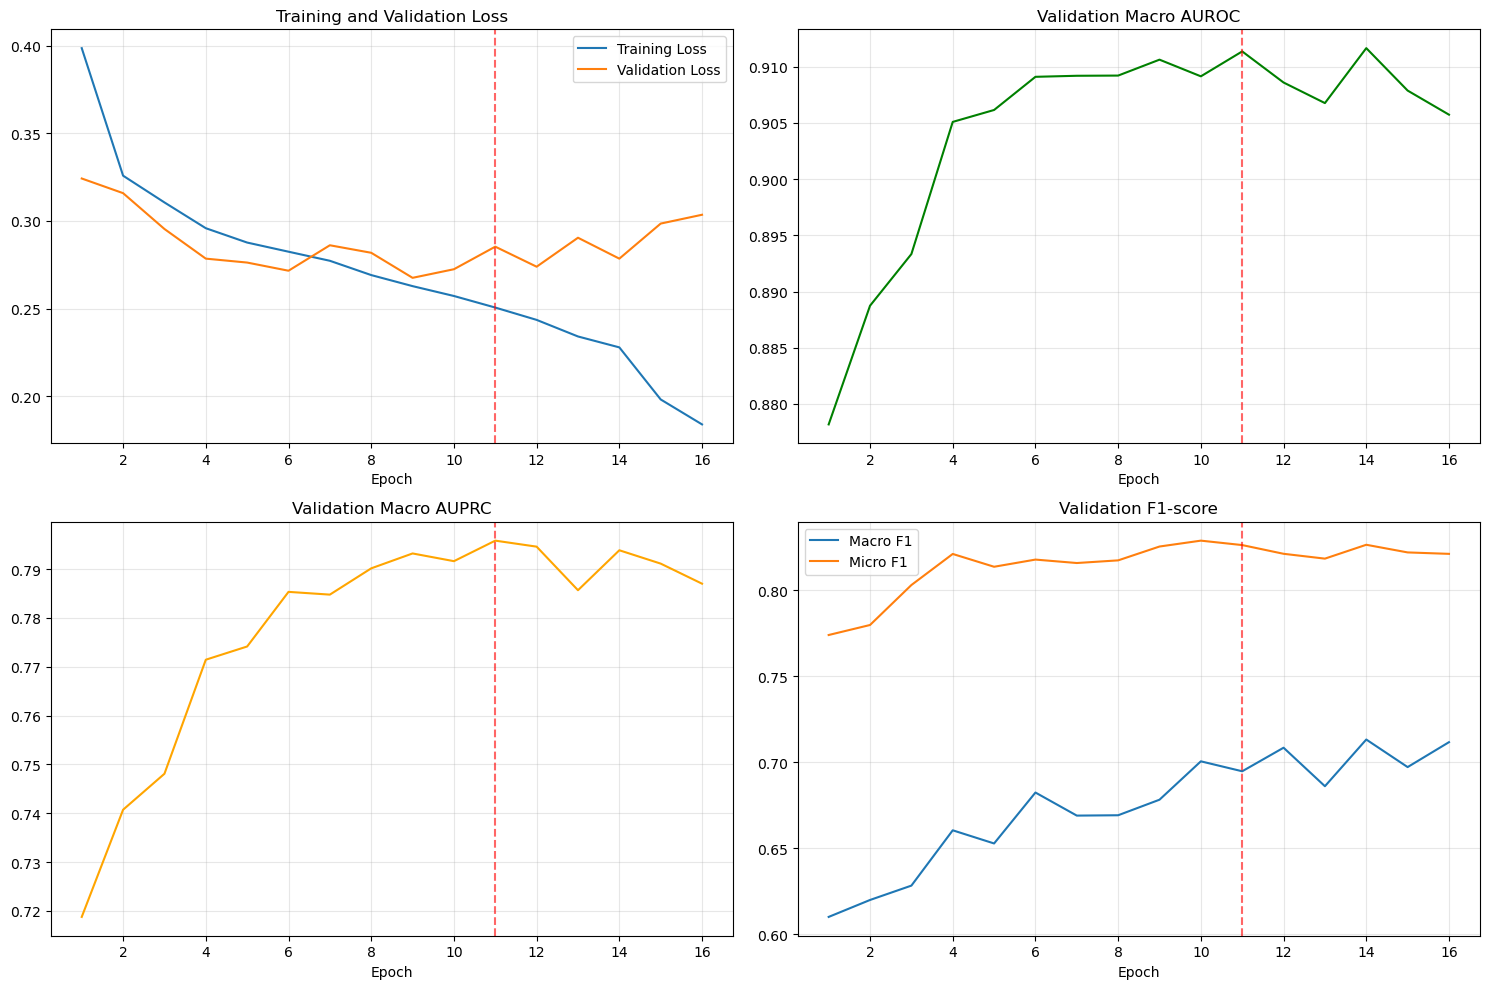

In [54]:
epochs = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Loss
axes[0, 0].plot(
    epochs, history["train_loss"], label="Training Loss"
)
axes[0, 0].plot(
    epochs, history["val_loss"], label="Validation Loss"
)
axes[0, 0].set_title("Training and Validation Loss")
axes[0, 0].legend()

# AUROC
axes[0, 1].plot(
    epochs, history["macro_auroc"], color="green"
)
axes[0, 1].set_title("Validation Macro AUROC")

# AUPRC
axes[1, 0].plot(
    epochs, history["macro_auprc"], color="orange"
)
axes[1, 0].set_title("Validation Macro AUPRC")

# F1
axes[1, 1].plot(
    epochs, history["macro_f1"], label="Macro F1"
)
axes[1, 1].plot(
    epochs, history["micro_f1"], label="Micro F1"
)
axes[1, 1].set_title("Validation F1-score")
axes[1, 1].legend()

for ax in axes.flat:

    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.3)
    ax.axvline(
        best_epoch,
        color="red",
        linestyle="--",
        alpha=0.6
    )

plt.tight_layout()
plt.show()

In [55]:
model.load_state_dict(
    torch.load(
        BEST_MODEL_PATH,
        map_location=device
    )
)

model.to(device)

cnn_metrics, cnn_val_targets, cnn_val_probs = evaluate_model(
    model,
    val_loader,
    criterion
)

cnn_val_preds = (cnn_val_probs >= 0.5).astype(int)

assert np.array_equal(cnn_val_targets, y_val)

print("Best CNN Validation Results")
print("-" * 40)

for metric, value in cnn_metrics.items():

    print(f"{metric}: {value:.4f}")

Best CNN Validation Results
----------------------------------------
loss: 0.2853
macro_auroc: 0.9114
macro_auprc: 0.7958
macro_f1: 0.6948
micro_f1: 0.8264


,Number of labels,Model,Macro AUROC,Macro AUPRC,Macro F1,Micro F1
0,5,Logistic Regression,0.8496,0.6879,0.5925,0.7471
1,5,SVM,0.8531,0.6933,0.6036,0.7575
2,5,Random Forest,0.8563,0.6938,0.5690,0.7520
3,5,2D CNN,0.9114,0.7958,0.6948,0.8264


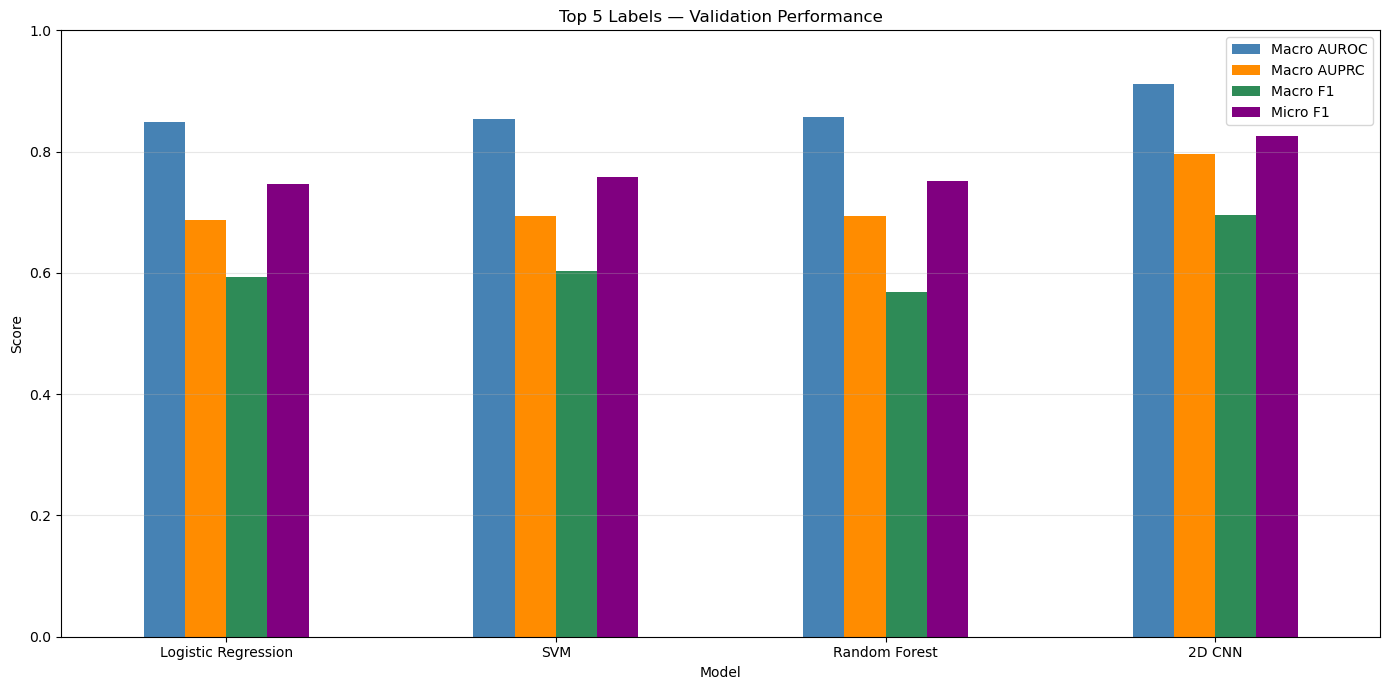

In [56]:
cnn_results = pd.DataFrame([{
    "Model": "2D CNN",
    "Macro AUROC": cnn_metrics["macro_auroc"],
    "Macro AUPRC": cnn_metrics["macro_auprc"],
    "Macro F1": cnn_metrics["macro_f1"],
    "Micro F1": cnn_metrics["micro_f1"]
}])

final_val_results = pd.concat(
    [results, cnn_results],
    ignore_index=True
)

final_val_results.insert(0, "Number of labels", NUM_LABELS)

display(final_val_results.round(4))

final_val_results.to_csv(
    MODEL_DIR / "validation_model_comparison.csv",
    index=False
)

final_val_results.drop(columns="Number of labels").set_index("Model").plot(
    kind="bar",
    figsize=(14, 7),
    ylim=(0, 1),
    rot=0,
    color=["steelblue", "darkorange", "seagreen", "purple"]
)

plt.title(f"Top {NUM_LABELS} Labels — Validation Performance")
plt.ylabel("Score")
plt.grid(axis="y", alpha=0.3)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()


## Per-label evaluation

In [57]:
model_scores = {
    "Logistic Regression": (lr_val_probs, 0.5),
    "SVM": (svm_val_scores, 0.0),
    "Random Forest": (rf_val_probs, 0.5),
    "2D CNN": (cnn_val_probs, 0.5)
}

per_label_results = []

for name, (scores, threshold) in model_scores.items():

    preds = (scores >= threshold).astype(int)

    for i, label in enumerate(selected_labels):

        per_label_results.append({
            "Model": name,
            "Label": label,
            "Validation positives": int(y_val[:, i].sum()),
            "AUROC": roc_auc_score(y_val[:, i], scores[:, i]),
            "AUPRC": average_precision_score(y_val[:, i], scores[:, i]),
            "F1": f1_score(
                y_val[:, i], preds[:, i],
                zero_division=0
            )
        })

    np.savez(
        MODEL_DIR / f"{name.lower().replace(' ', '_')}_validation.npz",
        scores=scores,
        targets=y_val,
        labels=np.asarray(selected_labels),
        ecg_ids=val_df["ecg_id"].to_numpy(),
        threshold=threshold
    )

per_label_results = pd.DataFrame(per_label_results)

display(per_label_results.round(4))

per_label_results.to_csv(
    MODEL_DIR / "per_label_validation_results.csv",
    index=False
)


,Model,Label,Validation positives,AUROC,AUPRC,F1
0,Logistic Regression,label_NSR,1253,0.8388,0.8584,0.8097
1,Logistic Regression,label_AB,1069,0.9205,0.9307,0.8454
2,Logistic Regression,label_NML,635,0.8827,0.7366,0.6417
3,Logistic Regression,label_SBRAD,317,0.9416,0.7099,0.6351
4,Logistic Regression,label_SRTH,255,0.6645,0.2038,0.0304
5,SVM,label_NSR,1253,0.8446,0.8636,0.8205
6,SVM,label_AB,1069,0.9237,0.9333,0.8455
7,SVM,label_NML,635,0.8890,0.7475,0.6712
8,SVM,label_SBRAD,317,0.9444,0.7184,0.6655
9,SVM,label_SRTH,255,0.6637,0.2040,0.0153


## Evaluation on the five common labels

In [58]:
common_results = []

for name, (scores, threshold) in model_scores.items():

    targets = y_val[:, :5]
    scores_5 = scores[:, :5]
    preds = (scores_5 >= threshold).astype(int)

    common_results.append({
        "Number of labels": NUM_LABELS,
        "Model": name,
        "Macro AUROC": roc_auc_score(
            targets, scores_5, average="macro"
        ),
        "Macro AUPRC": average_precision_score(
            targets, scores_5, average="macro"
        ),
        "Macro F1": f1_score(
            targets, preds,
            average="macro", zero_division=0
        ),
        "Micro F1": f1_score(
            targets, preds,
            average="micro", zero_division=0
        )
    })

common_results = pd.DataFrame(common_results)

display(common_results.round(4))

common_results.to_csv(
    MODEL_DIR / "common_top5_results.csv",
    index=False
)


,Number of labels,Model,Macro AUROC,Macro AUPRC,Macro F1,Micro F1
0,5,Logistic Regression,0.8496,0.6879,0.5925,0.7471
1,5,SVM,0.8531,0.6933,0.6036,0.7575
2,5,Random Forest,0.8563,0.6938,0.5690,0.7520
3,5,2D CNN,0.9114,0.7958,0.6948,0.8264


## Comparison of 5, 10 and 53 labels

In [59]:
comparison = []

for n in [5, 10]:

    path = DATA_DIR / f"top_{n}" / "validation_model_comparison.csv"

    if path.exists():

        comparison.append(pd.read_csv(path))

# Include the previously saved 53-label results.
path_53 = DATA_DIR / "validation_model_comparison.csv"

if path_53.exists():

    results_53 = pd.read_csv(path_53)

    if "Number of labels" not in results_53.columns:

        results_53.insert(0, "Number of labels", 53)

    if "SVM" not in results_53["Model"].values:

        svm_path = DATA_DIR / "linear_svm.pkl"

        if svm_path.exists():

            svm_53 = joblib.load(svm_path)

            y_val_53 = val_df[original_labels].to_numpy(dtype=np.uint8)

            scores_53 = svm_53.decision_function(X_val)
            preds_53 = (scores_53 >= 0).astype(int)

            svm_result_53 = pd.DataFrame([{
                "Number of labels": 53,
                "Model": "SVM",
                "Macro AUROC": roc_auc_score(
                    y_val_53, scores_53, average="macro"
                ),
                "Macro AUPRC": average_precision_score(
                    y_val_53, scores_53, average="macro"
                ),
                "Macro F1": f1_score(
                    y_val_53, preds_53,
                    average="macro", zero_division=0
                ),
                "Micro F1": f1_score(
                    y_val_53, preds_53,
                    average="micro", zero_division=0
                )
            }])

            results_53 = pd.concat(
                [results_53, svm_result_53],
                ignore_index=True
            )

    comparison.append(results_53)

comparison = pd.concat(comparison, ignore_index=True)

display(comparison.round(4))

comparison.to_csv(
    DATA_DIR / "top5_top10_53_model_comparison.csv",
    index=False
)


,Number of labels,Model,Macro AUROC,Macro AUPRC,Macro F1,Micro F1
0,5,Logistic Regression,0.8496,0.6879,0.5925,0.7471
1,5,SVM,0.8531,0.6933,0.6036,0.7575
2,5,Random Forest,0.8563,0.6938,0.5690,0.7520
3,5,2D CNN,0.9114,0.7958,0.6948,0.8264
4,53,Logistic Regression,0.8652,0.3369,0.2258,0.5839
5,53,Random Forest,0.8547,0.3219,0.1491,0.5608
6,53,2D CNN,0.9231,0.4896,0.3783,0.7018
7,53,SVM,0.8537,0.3382,0.2154,0.5893


In [60]:
comparison_table = comparison.pivot(
    index="Model",
    columns="Number of labels",
    values=[
        "Macro AUROC",
        "Macro AUPRC",
        "Macro F1",
        "Micro F1"
    ]
)

display(comparison_table.round(4))


Macro AUROC         Macro AUPRC         Macro F1          \
Number of labels             5       53          5       53       5       53   
Model                                                                          
2D CNN                   0.9114  0.9231      0.7958  0.4896   0.6948  0.3783   
Logistic Regression      0.8496  0.8652      0.6879  0.3369   0.5925  0.2258   
Random Forest            0.8563  0.8547      0.6938  0.3219   0.5690  0.1491   
SVM                      0.8531  0.8537      0.6933  0.3382   0.6036  0.2154   

                    Micro F1          
Number of labels          5       53  
Model                                 
2D CNN                0.8264  0.7018  
Logistic Regression   0.7471  0.5839  
Random Forest         0.7520  0.5608  
SVM                   0.7575  0.5893

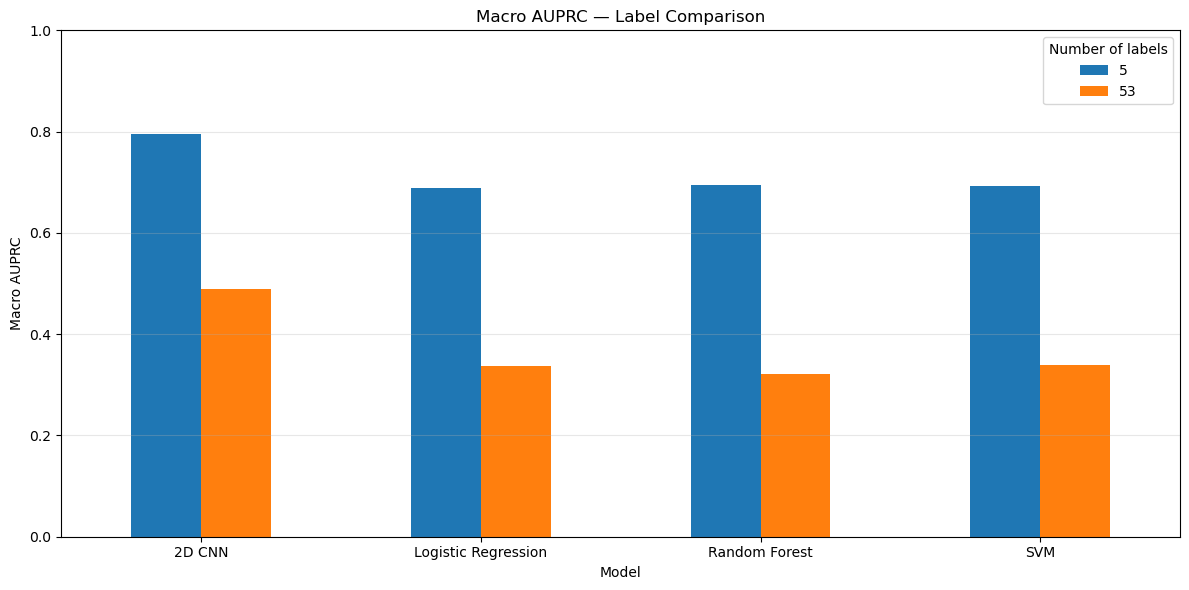

In [61]:
comparison.pivot(
    index="Model",
    columns="Number of labels",
    values="Macro AUPRC"
).plot(kind="bar", figsize=(12, 6), ylim=(0, 1), rot=0)

plt.title("Macro AUPRC — Label Comparison")
plt.ylabel("Macro AUPRC")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


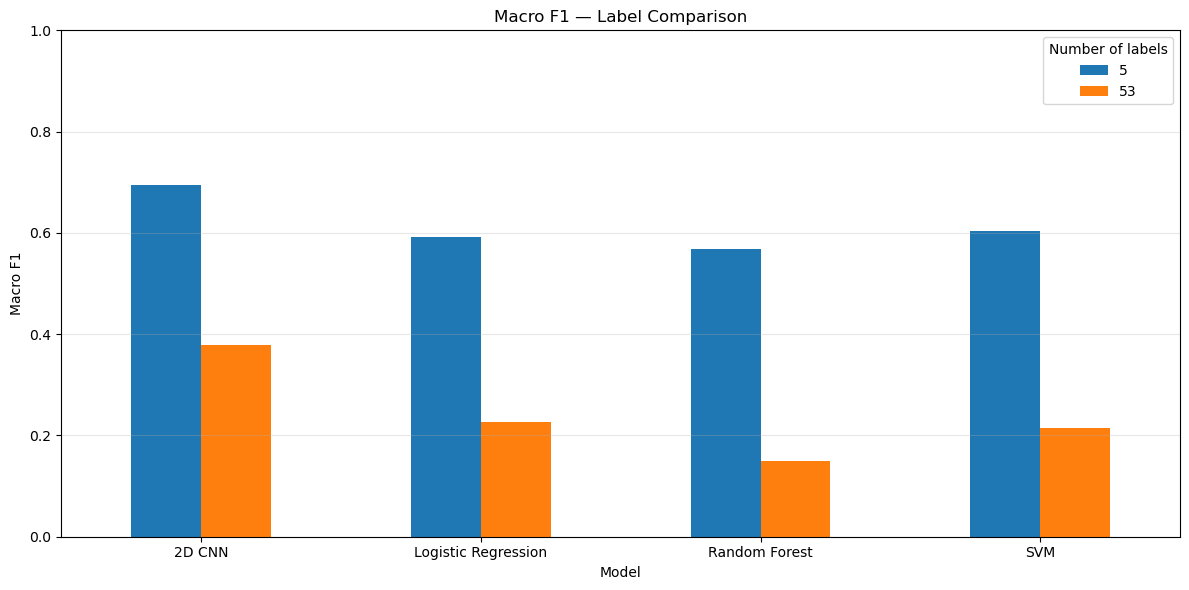

In [62]:
comparison.pivot(
    index="Model",
    columns="Number of labels",
    values="Macro F1"
).plot(kind="bar", figsize=(12, 6), ylim=(0, 1), rot=0)

plt.title("Macro F1 — Label Comparison")
plt.ylabel("Macro F1")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


## Top 5 vs Top 10 on common labels

In [63]:
path_5 = DATA_DIR / "top_5" / "common_top5_results.csv"
path_10 = DATA_DIR / "top_10" / "common_top5_results.csv"

if path_5.exists() and path_10.exists():

    with open(DATA_DIR / "top_5" / "selected_labels.json") as f:

        labels_5 = json.load(f)

    with open(DATA_DIR / "top_10" / "selected_labels.json") as f:

        labels_10 = json.load(f)

    assert labels_5 == labels_10[:5]

    common_comparison = pd.concat(
        [pd.read_csv(path_5), pd.read_csv(path_10)],
        ignore_index=True
    )

    display(common_comparison.round(4))

    common_comparison.to_csv(
        DATA_DIR / "common_top5_image_comparison.csv",
        index=False
    )
